# EDA - RAG-Based Document Q&A System (Project 72)
**HCLTech Career Shaper Programme 2025-26** | Domain: LLM / Python

This notebook explores `data/dataset.csv` (5,000 chunk-level records: 500 original + 4,500 synthetic rows) and then checks the **real** retrieval experiment run on the 50-document corpus. It contains 8 visualisations (the brief asks for 3+).

**How to run:** open from the project folder (`jupyter notebook`) and choose *Run All*. Figures are saved to `figures/`.

In [ ]:
import os, warnings, json
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
warnings.filterwarnings('ignore'); sns.set_theme(style='whitegrid', context='notebook')
ROOT = os.path.abspath('..') if os.path.basename(os.getcwd()) == 'notebooks' else os.path.abspath('.')
FIG = os.path.join(ROOT, 'figures'); os.makedirs(FIG, exist_ok=True)
df = pd.read_csv(os.path.join(ROOT, 'data', 'dataset_features.csv'))
def save(name): plt.tight_layout(); plt.savefig(os.path.join(FIG, name), dpi=140); plt.show()
print(df.shape)
df.head()

(5000, 13)


,doc_id,doc_type,chunk_id,word_count,retrieval_score,query_type,answer_quality_score,length_bucket,retrieval_band,quality_band,combined_score,hallucination_risk,category
0,DOC002,Markdown,CHK00001,457,0.5962,analytical,0.942,very_long(>450),low(<0.6),good(>0.85),0.7691,1,Constitution
1,DOC034,TXT,CHK00002,302,0.7397,factual,0.976,long(301-450),fair(0.6-0.75),good(>0.85),0.8578,0,Govt schemes
2,DOC013,Markdown,CHK00003,52,0.7735,comparative,0.660,short(<=150),good(0.75-0.9),poor(<0.7),0.7168,0,Constitution
3,DOC010,HTML,CHK00004,130,0.6278,comparative,0.910,short(<=150),fair(0.6-0.75),good(>0.85),0.7689,0,Constitution
4,DOC025,Markdown,CHK00005,220,0.7817,procedural,0.709,medium(151-300),good(0.75-0.9),ok(0.7-0.85),0.7454,0,Govt schemes


## 1. Data quality checks

In [ ]:
print(json.dumps(json.load(open(os.path.join(ROOT,'data','cleaning_report.json'))), indent=2))
print('\nMissing values per column:'); print(df.isna().sum()[df.isna().sum()>0] if df.isna().sum().sum() else 'none')
df[['word_count','retrieval_score','answer_quality_score','combined_score']].describe().round(3)

{
  "rows_in": 5000,
  "missing_values": 0,
  "duplicate_rows": 0,
  "duplicate_chunk_ids": 0,
  "unknown_doc_ids": 0,
  "doc_ids_with_multiple_types_before": 50,
  "doc_type_rows_corrected": 390,
  "out_of_range_rows_dropped": 0,
  "rows_out": 5000,
  "hallucination_risk_rate": 0.296
}

Missing values per column:
none


,word_count,retrieval_score,answer_quality_score,combined_score
count,5000.000,5000.000,5000.000,5000.000
mean,271.372,0.748,0.800,0.774
std,129.849,0.143,0.115,0.092
min,50.000,0.500,0.600,0.557
25%,159.000,0.624,0.699,0.706
50%,272.500,0.748,0.802,0.774
75%,385.000,0.869,0.900,0.840
max,499.000,0.999,1.000,0.994


**Reading:** no missing values or duplicates. The raw file had every `doc_id` mapped to 3-5 different `doc_type` values, which is impossible for one real file, so `doc_type` was aligned with the corpus manifest during cleaning (see report, section 5).

## 2. Distributions of the numeric columns (Figure 1)

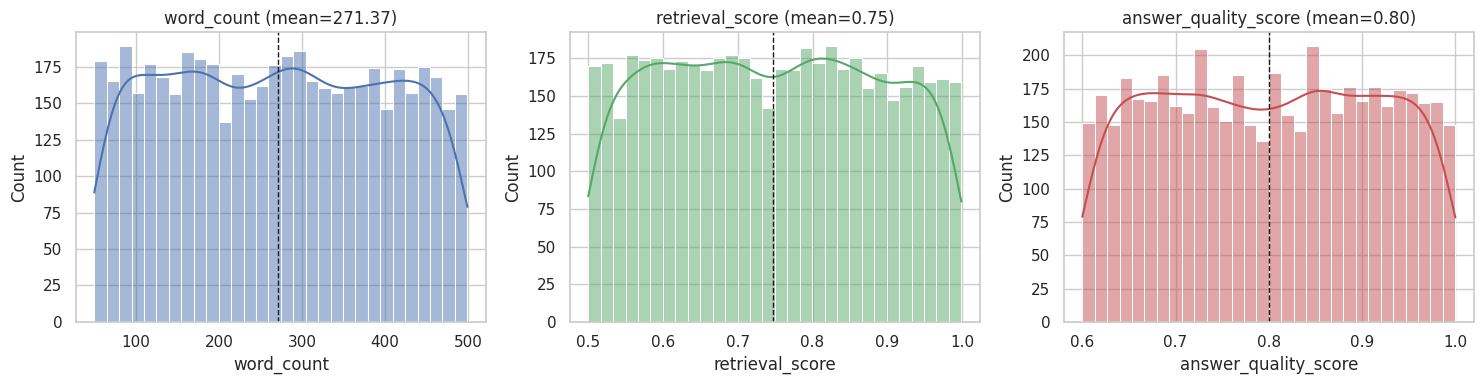

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, c, col in zip(ax, ['word_count', 'retrieval_score', 'answer_quality_score'], ['#4C72B0', '#55A868', '#C44E52']):
    sns.histplot(df[c], bins=30, kde=True, ax=a, color=col); a.axvline(df[c].mean(), color='k', ls='--', lw=1); a.set_title(f'{c} (mean={df[c].mean():.2f})')
save('fig1_distributions.png')

**Reading:** all three columns are almost flat (uniform): chunk length 50-499 words, retrieval score 0.50-1.00, answer quality 0.60-1.00. Real data would usually be skewed (many good scores, few bad).

## 3. Categorical balance (Figure 2)

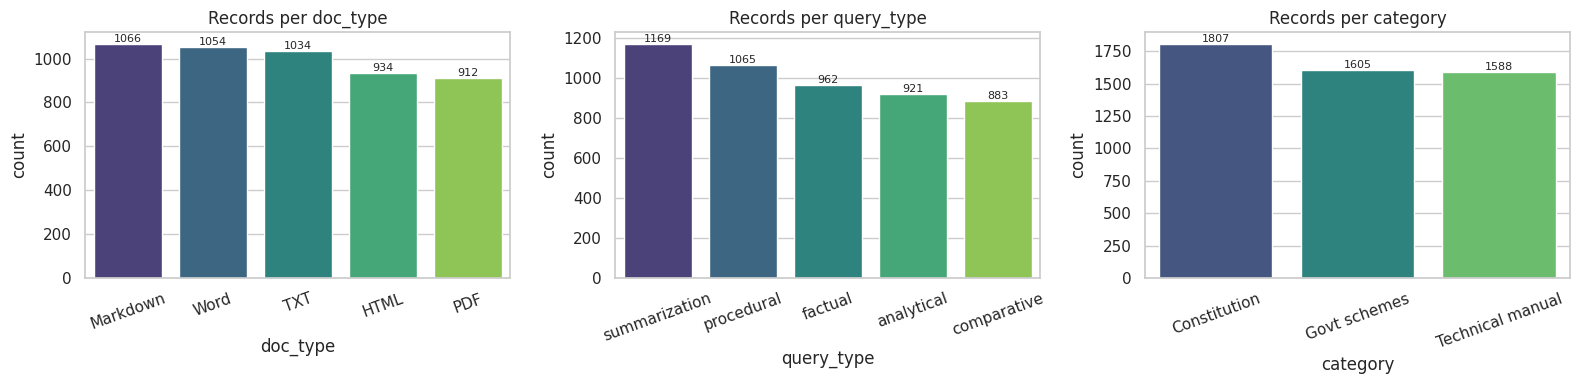

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
for a, c in zip(ax, ['doc_type', 'query_type', 'category']):
    order = df[c].value_counts().index; sns.countplot(data=df, x=c, order=order, ax=a, palette='viridis')
    a.set_title(f'Records per {c}'); a.tick_params(axis='x', rotation=20)
    for p in a.patches: a.annotate(int(p.get_height()), (p.get_x()+p.get_width()/2, p.get_height()), ha='center', va='bottom', fontsize=8)
save('fig2_categories.png')

## 4. Retrieval score and answer quality by question type (Figure 3)

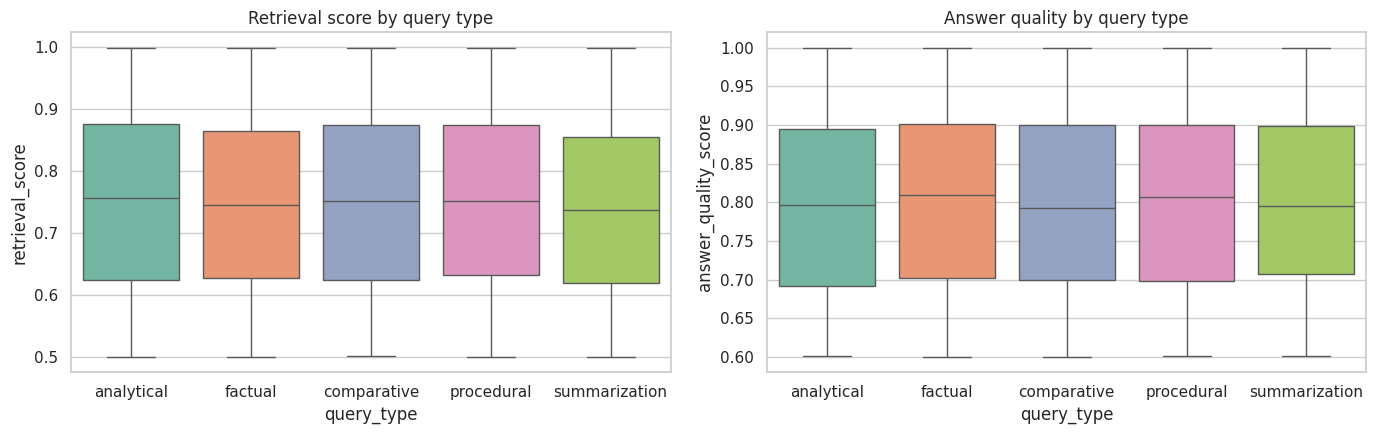

Kruskal-Wallis retrieval_score ~ query_type: H=5.24, p=0.264
Kruskal-Wallis answer_quality_score ~ query_type: H=2.08, p=0.721


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
sns.boxplot(data=df, x='query_type', y='retrieval_score', ax=ax[0], palette='Set2'); ax[0].set_title('Retrieval score by query type')
sns.boxplot(data=df, x='query_type', y='answer_quality_score', ax=ax[1], palette='Set2'); ax[1].set_title('Answer quality by query type')
save('fig3_by_query_type.png')
for c in ['retrieval_score', 'answer_quality_score']:
    H, p = stats.kruskal(*[g[c] for _, g in df.groupby('query_type')]); print(f'Kruskal-Wallis {c} ~ query_type: H={H:.2f}, p={p:.3f}')

**Reading:** medians are nearly equal for all five question types and the Kruskal-Wallis tests are not significant (p > 0.05), so in this dataset no question type is clearly harder than another.

## 5. Correlation (Figure 4)

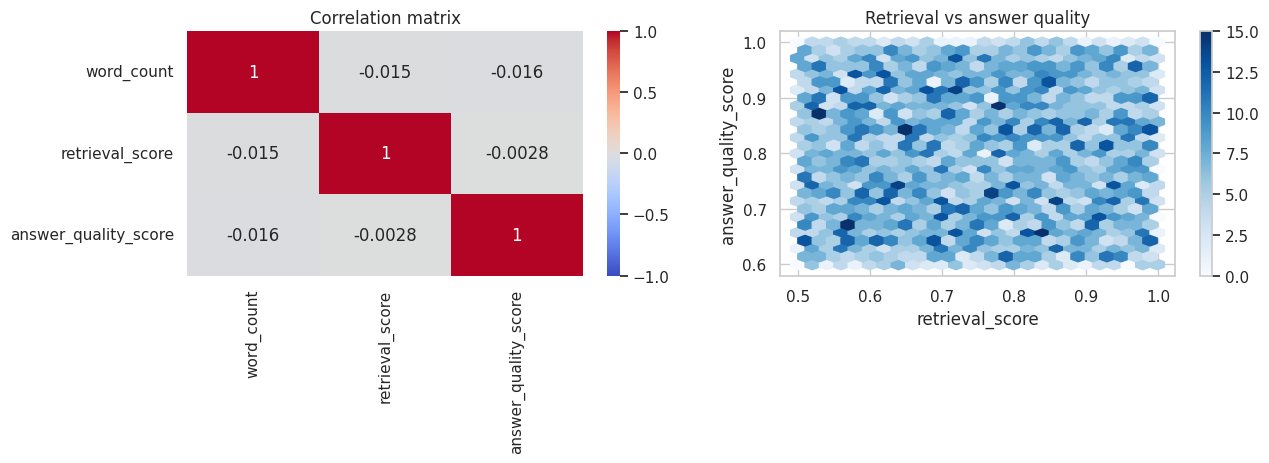

SignificanceResult(statistic=np.float64(-0.00257433219451918), pvalue=np.float64(0.8555924859937146))


In [ ]:
num = ['word_count', 'retrieval_score', 'answer_quality_score']
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
sns.heatmap(df[num].corr(), annot=True, cmap='coolwarm', vmin=-1, vmax=1, ax=ax[0]); ax[0].set_title('Correlation matrix')
hb = ax[1].hexbin(df.retrieval_score, df.answer_quality_score, gridsize=25, cmap='Blues'); plt.colorbar(hb, ax=ax[1]); ax[1].set_xlabel('retrieval_score'); ax[1].set_ylabel('answer_quality_score'); ax[1].set_title('Retrieval vs answer quality')
save('fig4_correlation.png')
print(stats.spearmanr(df.retrieval_score, df.answer_quality_score))

**Reading:** correlations are about 0. In a real RAG system better retrieval should give better answers, so this tells us the supplied/expanded dataset is **synthetic** (independent random columns). It is useful for practising EDA, but conclusions about real system behaviour must come from the real experiment in section 9.

## 6. Records that need human review (Figure 5)

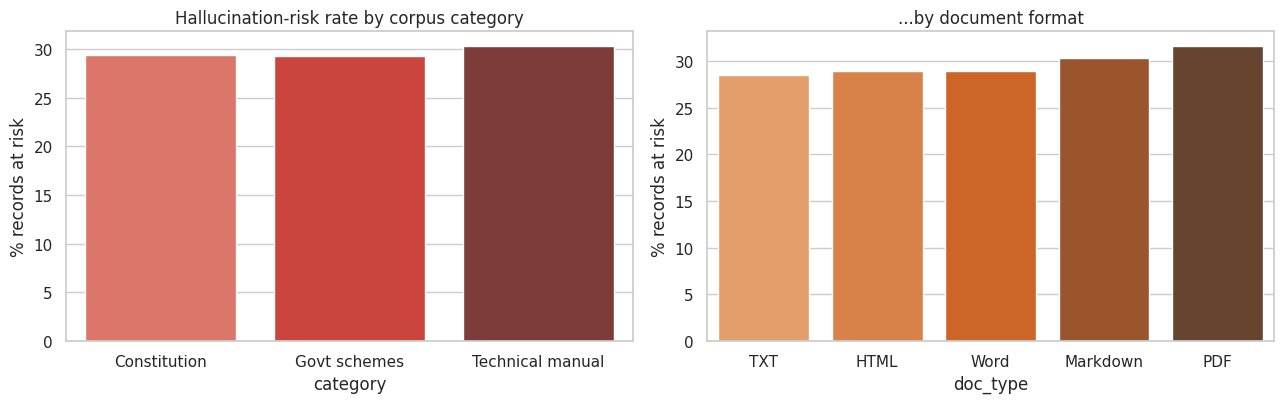

Overall risk rate: 29.6%  (rule: retrieval_score < 0.6 or answer_quality_score < 0.65)


In [ ]:
risk = df.groupby('category').hallucination_risk.mean().mul(100)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))
sns.barplot(x=risk.index, y=risk.values, ax=ax[0], palette='Reds_d'); ax[0].set_ylabel('% records at risk'); ax[0].set_title('Hallucination-risk rate by corpus category')
r2 = df.groupby('doc_type').hallucination_risk.mean().mul(100).sort_values(); sns.barplot(x=r2.index, y=r2.values, ax=ax[1], palette='Oranges_d'); ax[1].set_title('...by document format'); ax[1].set_ylabel('% records at risk')
save('fig5_risk.png'); print(f'Overall risk rate: {df.hallucination_risk.mean()*100:.1f}%  (rule: retrieval_score < 0.6 or answer_quality_score < 0.65)')

## 7. Outlier check (Figure 6)

{'word_count': 0, 'retrieval_score': 0, 'answer_quality_score': 0} <- IQR outliers per column


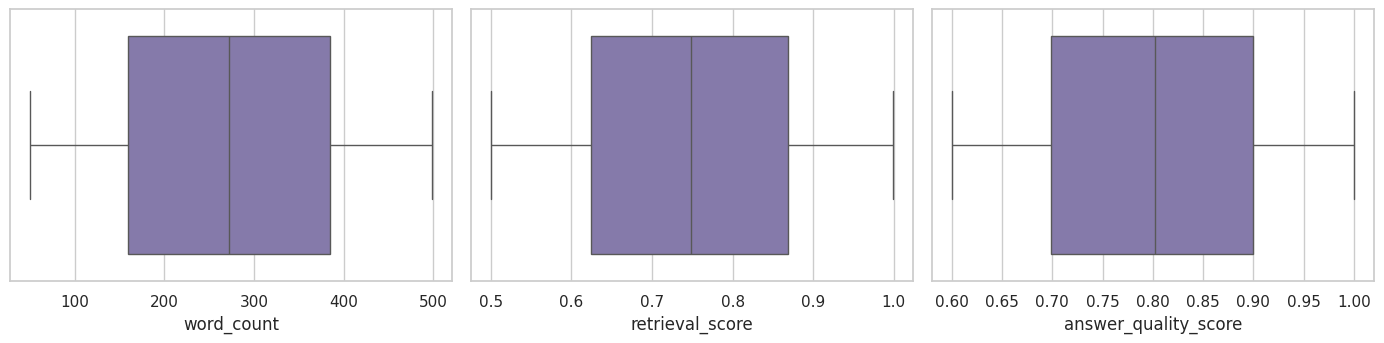

In [ ]:
def iqr_out(s): q1, q3 = s.quantile([.25, .75]); i = q3 - q1; return ((s < q1-1.5*i) | (s > q3+1.5*i)).sum()
print({c: int(iqr_out(df[c])) for c in ['word_count', 'retrieval_score', 'answer_quality_score']}, '<- IQR outliers per column')
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for a, c in zip(ax, ['word_count', 'retrieval_score', 'answer_quality_score']): sns.boxplot(x=df[c], ax=a, color='#8172B2')
save('fig6_outliers.png')

**Reading:** zero IQR outliers, consistent with bounded uniform data. Values stay inside valid ranges (scores within 0-1).

## 8. Per-document health (Figure 7)

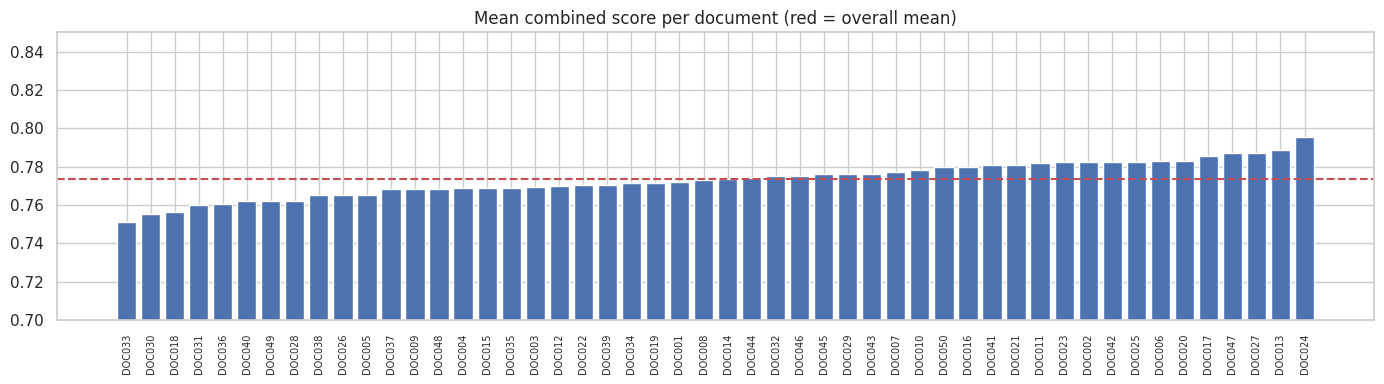

,chunks,retrieval,quality,combined
doc_id,,,,
DOC033,89,0.716,0.786,0.751
DOC030,93,0.727,0.783,0.755
DOC018,91,0.723,0.790,0.757
DOC031,96,0.738,0.782,0.760
DOC036,90,0.737,0.784,0.760


In [ ]:
d = df.groupby('doc_id').agg(chunks=('chunk_id', 'count'), retrieval=('retrieval_score', 'mean'), quality=('answer_quality_score', 'mean'), combined=('combined_score', 'mean')).sort_values('combined')
fig, ax = plt.subplots(figsize=(14, 4)); ax.bar(d.index, d.combined, color='#4C72B0'); ax.set_ylim(0.7, 0.85); ax.tick_params(axis='x', rotation=90, labelsize=7)
ax.axhline(d.combined.mean(), color='r', ls='--'); ax.set_title('Mean combined score per document (red = overall mean)'); save('fig7_per_document.png')
d.head(5).round(3)

## 9. REAL experiment: retrieval on the 50-document corpus (Figure 8)
These numbers come from `scripts/evaluate.py` and `scripts/ablation.py`, run on the 1,000 Q&A pairs in `data/qa_pairs.csv` (hashing embeddings, offline). Run both scripts first, and re-run with `--embedder minilm` for stronger results.

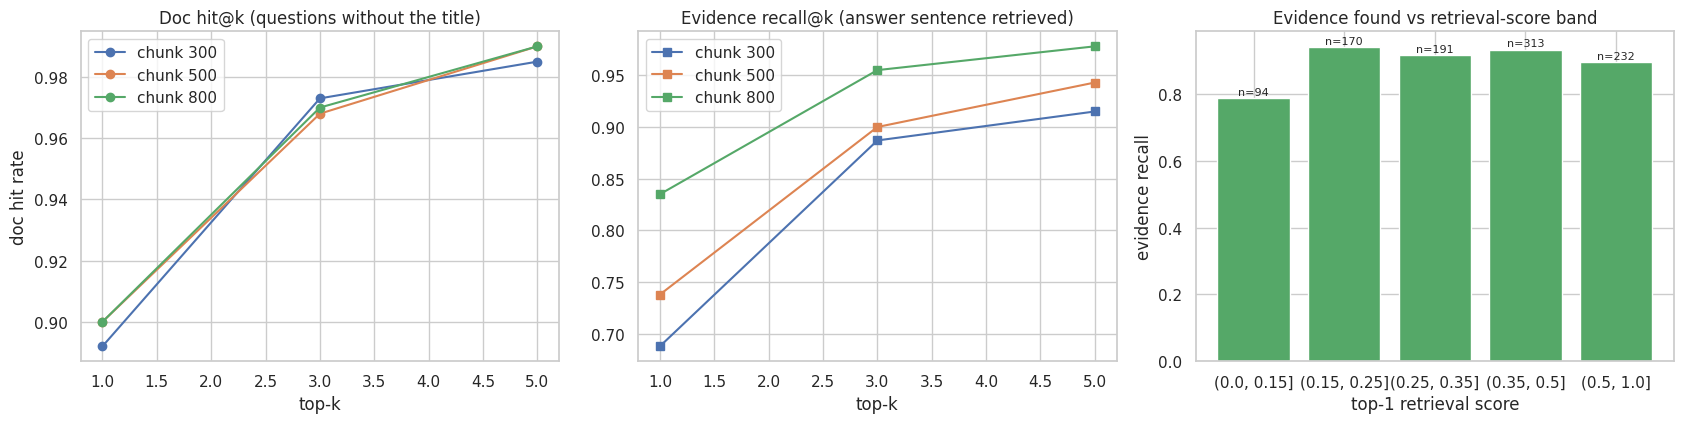

           band   mean  count
0   (0.0, 0.15]  0.787     94
1  (0.15, 0.25]  0.941    170
2  (0.25, 0.35]  0.916    191
3   (0.35, 0.5]  0.933    313
4    (0.5, 1.0]  0.897    232


In [ ]:
ab = pd.read_csv(os.path.join(ROOT, 'data', 'ablation_results.csv'))
ev = pd.read_csv(os.path.join(ROOT, 'data', 'eval_results.csv'))
fig, ax = plt.subplots(1, 3, figsize=(17, 4.4))
hard = ab[ab.subset == 'hard_no_title']
for cs, g in hard.groupby('chunk_size'): ax[0].plot(g.k, g.doc_hit, marker='o', label=f'chunk {cs}')
ax[0].set_title('Doc hit@k (questions without the title)'); ax[0].set_xlabel('top-k'); ax[0].set_ylabel('doc hit rate'); ax[0].legend()
for cs, g in hard.groupby('chunk_size'): ax[1].plot(g.k, g.evidence_recall, marker='s', label=f'chunk {cs}')
ax[1].set_title('Evidence recall@k (answer sentence retrieved)'); ax[1].set_xlabel('top-k'); ax[1].legend()
ev['band'] = pd.cut(ev.top_score, [0, .15, .25, .35, .5, 1]); b = ev.groupby('band', observed=True).evidence_hit.agg(['mean', 'count']).reset_index()
ax[2].bar(b.band.astype(str), b['mean'], color='#55A868'); ax[2].set_title('Evidence found vs retrieval-score band'); ax[2].set_ylabel('evidence recall'); ax[2].set_xlabel('top-1 retrieval score')
for i, r in b.iterrows(): ax[2].text(i, r['mean'] + .01, f"n={r['count']}", ha='center', fontsize=8)
save('fig8_real_retrieval.png'); print(b.round(3))

**Reading:** (a) larger chunks (800 characters) find the answer sentence more often, and going from top-k 3 to 5 adds only about 1-2 points of document hit rate; (b) when the best retrieval score is very low (0.15 or below) the evidence is found far less often (about 79%) than when it is above 0.15 (about 90-94%). The relationship is a threshold effect, not a smooth rise, and it is **absent in the synthetic dataset** - this supports the app's *minimum retrieval score* refusal rule.

## 10. Summary of findings
1. Dataset is clean (no missing values or duplicates) after aligning `doc_type` to the real file format of each document.
2. All numeric columns are uniformly distributed and uncorrelated -> synthetic; no question type or file format is significantly harder.
3. About 30% of records meet the *hallucination-risk* rule and would need human review - another reason to always show the source chunk.
4. On the real corpus, retrieval works well (see section 9), and a very low retrieval score is a useful signal for deciding when to refuse to answer.